<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/notebooks/05_model_family_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · 05 · Bounded models comparison

**Purpose:** compare model families after A (training data composition analysis) selected all-history eligibility and B (class imbalance treatment) selected 10:1 undersampling by validation AP. Preserve unweighted all-history LightGBM as a reference: Stage B improved AP (0.18567 → 0.19221), but slightly reduced recall at 5% FPR (54.36% → 54.12%).

Train using months 0–4; select using month 5. **Months 6–7 are excluded.** This notebook does not perform ensemble selection or final testing.

1. Seed 42: fit two fixed LightGBM references, fixed logistic regression, four CatBoost candidates and four XGBoost candidates (**11 fits**).
2. Select the best candidate within each new family by month-5 AP; retain the fixed references. Repeat these five configurations on seeds 43 and 44 (**10 additional fits**, reusing seed-42 fits).
3. Choose the strongest new family by three-seed mean AP under 10:1 undersampling. Fit its selected configuration on all eligible rows without undersampling for all three seeds (**3 fits**).

**Total: 24 fits.** This is a bounded comparison of pipelines under the stated budgets, not proof of each algorithm's best possible performance. The three-seed results include the seed used to select configurations and remain development estimates.

Run top to bottom in Colab CPU or locally after data preparation. No previous model artifacts or `src/` code are needed. Saved predictions and fitted pipelines support the later ensemble notebook. Keep this notebook's validation frame and row IDs aligned across all models.


## 1. Locations

Use the existing prepared pair in `MyDrive/BT4012_grp_proj/processed/` on Colab or `data/processed/` locally. Put this notebook in the repository's `notebooks/` folder. No raw CSV or rerun of preparation is needed if the prepared files are unchanged.


In [ ]:
import sys
from pathlib import Path

# Detect the runtime; local execution does not require google.colab.
IN_COLAB = 'google.colab' in sys.modules

# Colab: keep Base.csv directly inside this existing Drive project folder.
DRIVE_PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')

# Local: normally leave None; set an absolute repo path if auto-detection fails.
LOCAL_REPO_ROOT = None

if IN_COLAB:
    from google.colab import drive

    drive.mount('/content/drive')
    PROJECT_DIR = DRIVE_PROJECT_DIR
    RAW_PATH = PROJECT_DIR / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'processed'
else:
    if LOCAL_REPO_ROOT is not None:
        PROJECT_DIR = Path(LOCAL_REPO_ROOT).expanduser().resolve()
    else:
        working_dir = Path.cwd().resolve()
        candidates = [working_dir, *working_dir.parents]
        PROJECT_DIR = next(
            (
                candidate
                for candidate in candidates
                if (candidate / 'notebooks').is_dir()
                and (candidate / 'data').is_dir()
            ),
            working_dir,
        )

    RAW_PATH = PROJECT_DIR / 'data' / 'Base.csv'
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'

CLEAN_PATH = PROCESSED_DIR / 'baf_clean.parquet'
MANIFEST_PATH = PROCESSED_DIR / 'preparation_manifest.json'

print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Python')
print('Project:', PROJECT_DIR)
print('Raw CSV:', RAW_PATH)
print('Prepared data:', CLEAN_PATH)


Mounted at /content/drive
Runtime: Google Colab
Project: /content/drive/MyDrive/BT4012_grp_proj
Raw CSV: /content/drive/MyDrive/BT4012_grp_proj/Base.csv
Prepared data: /content/drive/MyDrive/BT4012_grp_proj/processed/baf_clean.parquet


## 2. Dependencies and run configuration

Colab installs missing packages only. Locally install `numpy pandas scikit-learn matplotlib joblib pyarrow lightgbm catboost xgboost` in your notebook environment (sklearn ≥1.3, LightGBM ≥4, CatBoost ≥1.2, XGBoost ≥2). If upgrading packages already imported into a runtime, restart the runtime before running all cells.

CPU and two threads are the default. Models/predictions are saved so C2 does not require retraining. Each run gets a new output directory. Checkpoint CSVs survive later failures, but this notebook does not automatically resume interrupted runs. CatBoost can take longer than the previous LightGBM experiments.

Keep the predefined grid and seeds for the reported experiment. No early stopping is used: iteration counts are fixed candidates and month 5 is used only to score/select pipelines.


In [ ]:
import importlib.util
import subprocess

required_packages = {
    'lightgbm': 'lightgbm>=4.0', 'pyarrow': 'pyarrow>=14.0',
    'catboost': 'catboost>=1.2', 'xgboost': 'xgboost>=2.0',
}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]

if missing_packages:
    if IN_COLAB:
        subprocess.check_call([
            sys.executable, '-m', 'pip', 'install', '-q', *missing_packages,
        ])
    else:
        raise ImportError('Missing dependencies. Run: python -m pip install -r requirements.txt')

import hashlib
import json
import platform
import time
import warnings
from datetime import datetime, timezone
from uuid import uuid4

import joblib
import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
import catboost
import xgboost



SCREEN_SEED = 42
SEEDS = [42, 43, 44]
N_JOBS = 2
VERIFY_CHECKSUM = True
SAVE_MODELS = True
SAVE_PREDICTIONS = True
FPR_TARGET = 0.05
REVIEW_CAPACITIES = [0.01, 0.02, 0.05]
TRAIN_MONTHS = [0, 1, 2, 3, 4]
VALIDATION_MONTHS = [5]
NEGATIVES_PER_POSITIVE = 10
LOGREG_MAX_ITER = 2000
LGBM_TREES = 300

assert SEEDS[0] == SCREEN_SEED and len(SEEDS) == len(set(SEEDS))
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:6]
RUN_NAME = f'model_comparison_{run_id}'
RESULTS_DIR = PROJECT_DIR / 'results' / 'model_comparison' / RUN_NAME
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts' / 'model_comparison' / RUN_NAME
FIGURES_DIR = RESULTS_DIR / 'figures'

for directory in [RESULTS_DIR, ARTIFACTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=False)

plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200})
print('Results:', RESULTS_DIR)
print('Models and predictions:', ARTIFACTS_DIR)
print('Planned fits with default grid:', 24)


Results: /content/drive/MyDrive/BT4012_grp_proj/results/model_comparison/model_comparison_20261115T184401Z_8e91a0
Models and predictions: /content/drive/MyDrive/BT4012_grp_proj/artifacts/model_comparison/model_comparison_20261115T184401Z_8e91a0
Planned fits with default grid: 24


## 3. Load development data

Reuse the preparation manifest's ordered feature schema. Numeric missing-value decoding and constant-feature exclusion remain unchanged from A/B. Predictors exclude month, target and row ID. The checksum reads file bytes for integrity; filtered Parquet loading excludes held-out months from the modelling dataframe.


In [ ]:
def file_sha256(path):
    """Return a chunked SHA-256 digest to verify the prepared file matches its manifest."""
    digest = hashlib.sha256()

    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)

    return digest.hexdigest()


if not CLEAN_PATH.is_file() or not MANIFEST_PATH.is_file():
    raise FileNotFoundError('Run 00_data_preparation.ipynb first with the same project paths.')

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)

if manifest.get('schema_version') != 1:
    raise ValueError('Unsupported preparation manifest version.')

if VERIFY_CHECKSUM and file_sha256(CLEAN_PATH) != manifest['prepared_sha256']:
    raise ValueError('Parquet fingerprint differs from the manifest; rerun preparation.')


TARGET = manifest['target']
MONTH = manifest['month_column']
ROW_ID = manifest['row_id_column']
FEATURES = manifest['features']
NUMERICAL = manifest['numerical_features']
CATEGORICAL = manifest['categorical_features']

if manifest['split_months']['train'] != TRAIN_MONTHS:
    raise ValueError('This experiment expects training months 0–4.')

if manifest['split_months']['validation'] != VALIDATION_MONTHS:
    raise ValueError('This experiment expects validation month 5.')

if set(FEATURES) != set(NUMERICAL + CATEGORICAL):
    raise ValueError('Inconsistent feature lists in preparation manifest.')

if set(FEATURES) & {TARGET, MONTH, ROW_ID}:
    raise ValueError('Target, month or row ID cannot be predictors.')

df = pd.read_parquet(
    CLEAN_PATH,
    filters=[(MONTH, 'in', TRAIN_MONTHS + VALIDATION_MONTHS)],
)

if list(df.columns) != manifest['columns'] or not df[ROW_ID].is_unique:
    raise ValueError('Prepared schema or row identifiers are inconsistent.')

for column in CATEGORICAL:
    df[column] = df[column].astype(object).where(df[column].notna(), np.nan)

# Sort by original row ID to make sampling reproducible if parquet row order changes.
history = df[df[MONTH].isin(TRAIN_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
validation = df[df[MONTH].isin(VALIDATION_MONTHS)].sort_values(ROW_ID).reset_index(drop=True)
del df

for name, frame in [('train', history), ('validation', validation)]:
    if len(frame) != manifest['split_counts'][name]:
        raise ValueError(f'{name} row count differs from the preparation manifest.')

    if not frame[TARGET].isin([0, 1]).all() or frame[TARGET].nunique() != 2:
        raise ValueError(f'{name} must contain valid labels and both classes.')

X_validation = validation[FEATURES]
y_validation = validation[TARGET].to_numpy()
validation_ties = np.random.default_rng(2026).random(len(validation))

display(history.groupby(MONTH)[TARGET].agg(
    applications='size', frauds='sum', fraud_rate='mean',
))
print('Validation applications:', len(validation))
print('Validation frauds:', int(y_validation.sum()))
print('Predictors:', len(FEATURES))


,applications,frauds,fraud_rate
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222
4,127691,1452,0.011371


Validation applications: 119323
Validation frauds: 1411
Predictors: 29


## 4. Shared training samples and predefined candidates

For each seed, keep all training frauds plus ten randomly sampled legitimate applications per fraud. Exactly the same row IDs go to every undersampled family for that seed. This reproduces Stage B's permutation-and-prefix sampling rule. Full-history references use all eligible rows.

| Family / reference | Treatment | Search |
|---|---|---|
| LightGBM full | None | Fixed: 300 trees, 15 leaves, minimum child samples 100 |
| LightGBM 10:1 | Undersampling | Same fixed settings |
| Logistic regression 10:1 | Undersampling | Fixed C=0.1 |
| CatBoost 10:1 | Undersampling | depth {4, 6} × iterations {300, 600} |
| XGBoost 10:1 | Undersampling | max_depth {3, 5} × n_estimators {300, 600} |

The two new families use learning rate 0.05 and fixed regularisation settings. Four candidates per family is a deliberate time budget, not a claim of equivalent expressiveness or compute. Weighting is off everywhere. Logistic regression's C was selected on full data earlier; it is a fixed comparator here, not a retuned optimum for undersampling.


In [ ]:
positive_positions = np.flatnonzero(history[TARGET].to_numpy() == 1)
negative_positions = np.flatnonzero(history[TARGET].to_numpy() == 0)
n_positive = len(positive_positions)
n_keep_negative = NEGATIVES_PER_POSITIVE * n_positive

if n_keep_negative > len(negative_positions):
    raise ValueError('Not enough legitimate training rows for the chosen ratio.')

training_frames = {}
sample_records = []

for seed in SEEDS:
    negative_order = np.random.default_rng(seed).permutation(negative_positions)
    selected = np.concatenate([positive_positions, negative_order[:n_keep_negative]])
    subset = history.iloc[selected].sort_values(ROW_ID)

    assert subset[ROW_ID].is_unique
    assert int(subset[TARGET].sum()) == n_positive
    assert len(subset) == n_positive + n_keep_negative

    training_frames[seed] = subset
    subset[[ROW_ID]].to_parquet(ARTIFACTS_DIR / f'train_ids_rus10_seed_{seed}.parquet', index=False)
    sample_records.append({
        'seed': seed, 'rows': len(subset), 'frauds': n_positive,
        'fraud_rate': float(subset[TARGET].mean()),
        'row_ids_sha256': hashlib.sha256(
            subset[ROW_ID].to_numpy(dtype='<i8').tobytes()
        ).hexdigest(),
    })

history[[ROW_ID]].to_parquet(ARTIFACTS_DIR / 'train_ids_full.parquet', index=False)
validation[[ROW_ID, MONTH, TARGET]].to_parquet(
    ARTIFACTS_DIR / 'validation_index.parquet', index=False,
)
pd.DataFrame(sample_records).to_csv(RESULTS_DIR / 'training_samples.csv', index=False)

candidates = [
    {'id': 'lgbm_full', 'family': 'lightgbm', 'treatment': 'none',
     'params': {'num_leaves': 15, 'min_child_samples': 100}},
    {'id': 'lgbm_rus10', 'family': 'lightgbm', 'treatment': 'rus10',
     'params': {'num_leaves': 15, 'min_child_samples': 100}},
    {'id': 'logreg_rus10', 'family': 'logreg', 'treatment': 'rus10',
     'params': {'C': 0.1}},
]

for depth in [4, 6]:
    for iterations in [300, 600]:
        candidates.append({
            'id': f'cat_d{depth}_n{iterations}', 'family': 'catboost',
            'treatment': 'rus10', 'params': {'depth': depth, 'iterations': iterations},
        })

for depth in [3, 5]:
    for trees in [300, 600]:
        candidates.append({
            'id': f'xgb_d{depth}_n{trees}', 'family': 'xgboost',
            'treatment': 'rus10', 'params': {'max_depth': depth, 'n_estimators': trees},
        })

display(pd.DataFrame(candidates))


,id,family,treatment,params
0,lgbm_full,lightgbm,none,"{'num_leaves': 15, 'min_child_samples': 100}"
1,lgbm_rus10,lightgbm,rus10,"{'num_leaves': 15, 'min_child_samples': 100}"
2,logreg_rus10,logreg,rus10,{'C': 0.1}
3,cat_d4_n300,catboost,rus10,"{'depth': 4, 'iterations': 300}"
4,cat_d4_n600,catboost,rus10,"{'depth': 4, 'iterations': 600}"
5,cat_d6_n300,catboost,rus10,"{'depth': 6, 'iterations': 300}"
6,cat_d6_n600,catboost,rus10,"{'depth': 6, 'iterations': 600}"
7,xgb_d3_n300,xgboost,rus10,"{'max_depth': 3, 'n_estimators': 300}"
8,xgb_d3_n600,xgboost,rus10,"{'max_depth': 3, 'n_estimators': 600}"
9,xgb_d5_n300,xgboost,rus10,"{'max_depth': 5, 'n_estimators': 300}"


## 5. Model-specific pipelines

- **Logistic regression:** median imputation and missing indicators, standardisation, one-hot categorical encoding.
- **LightGBM:** unchanged numeric NaNs and training-fitted categorical codes explicitly declared categorical. Unseen categories map to −1.
- **XGBoost:** numeric NaNs plus **dense** one-hot categorical encoding. Explicit zeros remain zeros rather than sparse absent entries interpreted as missing. Unknown categories produce all-zero indicators. This intentionally uses a straightforward OHE pipeline rather than native categorical encoding.
- **CatBoost:** numeric NaNs plus categorical strings, with a constant string for missing categories. Original categorical columns are explicitly declared to CatBoost; its categorical processing is learned during fitting. No external target encoding.

Every pipeline fits preprocessing only on its own training rows. Inputs always use the manifest feature order. Pipelines use built-in sklearn transformers, making saved joblib files reloadable without a custom class defined in this notebook. Numeric columns precede categorical columns after transformation.

References: [CatBoostClassifier](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier), [XGBoost categorical alternatives](https://xgboost.readthedocs.io/en/stable/tutorials/categorical.html).


In [ ]:
def build_model(model_name, params, seed):
    """
    Build an unfitted model with preprocessing appropriate to its model family.

    Process:
    1. Define transformations without fitting any training statistics.
    2. Combine numeric/categorical transformations in a ColumnTransformer.
    3. Attach an unweighted classifier.

    Returns:
        Tuple: the estimator and additional fit arguments. LightGBM needs the
        transformed categorical column positions explicitly marked at fit time.
    """
    if model_name == 'logreg':
        numeric_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='median',
                add_indicator=True,
                keep_empty_features=True,
            )),
            ('scale', StandardScaler()),
        ])

        categorical_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='constant',
                fill_value='__MISSING__',
                keep_empty_features=True,
            )),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
        ])

        preprocessing = ColumnTransformer(
            transformers=[
                ('numeric', numeric_pipeline, NUMERICAL),
                ('categorical', categorical_pipeline, CATEGORICAL),
            ],
            sparse_threshold=1.0,
        )

        classifier = LogisticRegression(
            C=params['C'],
            solver='lbfgs',
            max_iter=LOGREG_MAX_ITER,
            class_weight=None,
            random_state=seed,
        )

        return Pipeline([
            ('preprocessing', preprocessing),
            ('classifier', classifier),
        ]), {}

    if model_name == 'lightgbm':
        categorical_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='constant',
                fill_value='__MISSING__',
                keep_empty_features=True,
            )),
            ('encode', OrdinalEncoder(
                handle_unknown='use_encoded_value',
                unknown_value=-1,
                dtype=np.int32,
            )),
        ])

        # ColumnTransformer puts numeric columns first and category codes second.
        preprocessing = ColumnTransformer([
            ('numeric', 'passthrough', NUMERICAL),
            ('categorical', categorical_pipeline, CATEGORICAL),
        ])

        classifier = LGBMClassifier(
            objective='binary',
            n_estimators=LGBM_TREES,
            learning_rate=0.05,
            num_leaves=params['num_leaves'],
            min_child_samples=params['min_child_samples'],
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            class_weight=None,
            scale_pos_weight=1.0,
            random_state=seed,
            n_jobs=N_JOBS,
            verbosity=-1,
        )

        categorical_positions = list(range(
            len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL),
        ))

        return Pipeline([
            ('preprocessing', preprocessing),
            ('classifier', classifier),
        ]), {'classifier__categorical_feature': categorical_positions}


    if model_name == 'xgboost':
        categorical_pipeline = Pipeline([
            ('impute', SimpleImputer(
                strategy='constant', fill_value='__MISSING__', keep_empty_features=True,
            )),
            ('encode', OneHotEncoder(
                handle_unknown='ignore', sparse_output=False, dtype=np.float32,
            )),
        ])
        preprocessing = ColumnTransformer([
            ('numeric', 'passthrough', NUMERICAL),
            ('categorical', categorical_pipeline, CATEGORICAL),
        ], sparse_threshold=0)
        classifier = XGBClassifier(
            objective='binary:logistic', tree_method='hist',
            n_estimators=params['n_estimators'], max_depth=params['max_depth'],
            learning_rate=0.05, min_child_weight=5,
            subsample=0.8, colsample_bytree=0.8,
            reg_lambda=1.0, reg_alpha=0.0, scale_pos_weight=1.0,
            eval_metric='logloss', random_state=seed, n_jobs=N_JOBS,
        )
        return Pipeline([
            ('preprocessing', preprocessing), ('classifier', classifier),
        ]), {}

    if model_name == 'catboost':
        preprocessing = ColumnTransformer([
            ('numeric', 'passthrough', NUMERICAL),
            ('categorical', SimpleImputer(
                strategy='constant', fill_value='__MISSING__', keep_empty_features=True,
            ), CATEGORICAL),
        ])
        categorical_positions = list(range(
            len(NUMERICAL), len(NUMERICAL) + len(CATEGORICAL),
        ))
        classifier = CatBoostClassifier(
            loss_function='Logloss', iterations=params['iterations'],
            depth=params['depth'], learning_rate=0.05, l2_leaf_reg=3.0,
            boosting_type='Plain', task_type='CPU',
            cat_features=categorical_positions, random_seed=seed,
            thread_count=N_JOBS, verbose=False, allow_writing_files=False,
        )
        return Pipeline([
            ('preprocessing', preprocessing), ('classifier', classifier),
        ]), {}

    raise ValueError(f'Unknown model: {model_name}')


## 6. Evaluation policy

AP is the primary criterion throughout. Recall at 5% FPR chooses the lowest empirical validation threshold satisfying the FPR ceiling. FPR is the fraction of **legitimate applications** flagged. It differs from a 5% review budget, which selects exactly 5% of all applications.

Each fitted model receives its own validation threshold. Exact top-K review metrics use the same label-independent tie breakers. Scores from undersampled models are not assumed to be calibrated probabilities. Their numeric thresholds need not resemble the full-data model's threshold.

Seed means describe separate fitted models, **not** a seed-averaged prediction ensemble. Saved predictions let C2 explore blending explicitly.


In [ ]:
def at_threshold(y_true, scores, threshold):
    """
    Return confusion counts and operating metrics at an unchanged score cutoff.
    A score equal to the cutoff is flagged; divisions with zero denominators return 0.
    """
    flagged = np.asarray(scores) >= threshold
    positive = np.asarray(y_true) == 1

    tp = int(np.sum(flagged & positive))
    fp = int(np.sum(flagged & ~positive))
    fn = int(np.sum(~flagged & positive))
    tn = int(np.sum(~flagged & ~positive))

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0

    return {
        'tp': tp,
        'fp': fp,
        'fn': fn,
        'tn': tn,
        'precision': precision,
        'recall': recall,
        'f1': 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        'fpr': fp / (fp + tn) if fp + tn else 0.0,
        'alert_rate': float(flagged.mean()),
    }


def threshold_for_fpr(y_true, scores, target_fpr):
    """
    Choose the least restrictive empirical cutoff satisfying an FPR ceiling.

    Evaluate every distinct ROC threshold on the supplied labeled split. This is
    deployable when supplied validation labels; using test labels instead defines
    a retrospective benchmark and must not be confused with a deployment threshold.
    """
    fpr, _, thresholds = roc_curve(y_true, scores, drop_intermediate=False)
    eligible = np.flatnonzero(fpr <= target_fpr)

    return float(thresholds[eligible[-1]])


def capacity_table(y_true, scores, capacities, tie_breakers):
    """
    Evaluate fraud captured when only an exact top-scoring budget is reviewed.

    Rank by descending score, then a label-independent tie breaker. Return review
    counts, precision, recall and true/false positives standardized per 10,000 apps.
    """
    y_true = np.asarray(y_true)
    order = np.lexsort((tie_breakers, -np.asarray(scores)))
    rows = []

    for capacity in capacities:
        n_review = int(np.floor(capacity * len(y_true)))
        reviewed_labels = y_true[order[:n_review]]
        tp = int(reviewed_labels.sum())
        fp = n_review - tp
        total_frauds = int(y_true.sum())

        rows.append({
            'capacity': capacity,
            'reviews': n_review,
            'precision': tp / n_review if n_review else 0.0,
            'recall': tp / total_frauds if total_frauds else 0.0,
            'frauds_flagged': tp,
            'legitimate_reviewed': fp,
            'frauds_missed': total_frauds - tp,
            'frauds_flagged_per_10000': 10000 * tp / len(y_true),
            'legitimate_reviewed_per_10000': 10000 * fp / len(y_true),
        })

    return pd.DataFrame(rows)


def ranking_metrics(y_true, scores, model_name):
    """Return ranking metrics; recall-at-FPR uses labels from this evaluation split."""
    recall_at_fpr = np.nan

    if model_name != 'dummy':
        benchmark_threshold = threshold_for_fpr(y_true, scores, FPR_TARGET)
        recall_at_fpr = at_threshold(y_true, scores, benchmark_threshold)['recall']

    return {
        'average_precision': float(average_precision_score(y_true, scores)),
        'roc_auc': float(roc_auc_score(y_true, scores)),
        'recall_at_target_fpr_benchmark': recall_at_fpr,
    }


## 7. Reusable fit, evaluate and checkpoint function

Every candidate is saved with its exact configuration, fit warnings, score cutoff and training row-ID fingerprint. Prediction rows follow `validation_index.parquet`. Checkpoint tables are updated after each fit; final status changes to complete only after the entire comparison and reporting finish.

Models are persisted as complete sklearn pipelines. XGBoost/CatBoost classifiers are additionally saved in native formats, but these native files alone do not include sklearn preprocessing. Keep compatible package versions when reloading, and only load trusted joblib files.


In [ ]:
def json_safe(value):
    """
    Convert nested results into standards-compliant JSON values.
    Nonfinite floats become null; threshold direction is recorded separately below.
    """
    if isinstance(value, dict):
        return {key: json_safe(item) for key, item in value.items()}

    if isinstance(value, (list, tuple)):
        return [json_safe(item) for item in value]

    if isinstance(value, (float, np.floating)) and not np.isfinite(value):
        return None

    if isinstance(value, np.generic):
        return value.item()

    return value



def write_json(filename, payload):
    """Write JSON with explicit nulls for nonfinite numeric values."""
    with open(RESULTS_DIR / filename, 'w', encoding='utf-8') as handle:
        json.dump(json_safe(payload), handle, indent=2, allow_nan=False)



run_info = {
    'run_name': RUN_NAME, 'status': 'running',
    'preparation_id': manifest['preparation_id'],
    'prepared_sha256': manifest['prepared_sha256'],
    'train_months': TRAIN_MONTHS, 'validation_months': VALIDATION_MONTHS,
    'test_evaluated': False, 'screen_seed': SCREEN_SEED, 'seeds': SEEDS,
    'selection_metric': 'validation average precision',
    'negative_positive_sampling_ratio': NEGATIVES_PER_POSITIVE,
    'fpr_target': FPR_TARGET, 'review_capacities': REVIEW_CAPACITIES,
    'n_jobs': N_JOBS, 'save_models': SAVE_MODELS,
    'save_predictions': SAVE_PREDICTIONS, 'candidates': candidates,
    'versions': {
        'python': platform.python_version(), 'pandas': pd.__version__,
        'numpy': np.__version__, 'sklearn': sklearn.__version__,
        'lightgbm': lightgbm.__version__, 'catboost': catboost.__version__,
        'xgboost': xgboost.__version__, 'joblib': joblib.__version__,
    },
}
write_json('run_info.json', run_info)
write_json('preparation_manifest.json', manifest)
metric_rows = []
capacity_frames = []
completed = set()


def run_fit(spec, seed, phase):
    """Fit once, evaluate on unchanged month 5, then save an auditable checkpoint.

    Reusing a (candidate ID, seed) skips an already completed in-memory fit.
    This prevents refitting selected seed-42 candidates during stability checks.
    It is not an on-disk resume mechanism.
    """
    key = (spec['id'], seed)
    if key in completed:
        return

    subset = history if spec['treatment'] == 'none' else training_frames[seed]
    estimator, fit_arguments = build_model(spec['family'], spec['params'], seed)
    start = time.perf_counter()

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        estimator.fit(subset[FEATURES], subset[TARGET], **fit_arguments)
        fit_seconds = time.perf_counter() - start
        scores = estimator.predict_proba(X_validation)[:, 1]

    warning_messages = list(dict.fromkeys(str(item.message) for item in caught))
    for message in warning_messages:
        print(f'WARNING [{spec["id"]}]: {message}')

    if not np.isfinite(scores).all():
        raise ValueError('Nonfinite validation predictions.')

    cutoff = threshold_for_fpr(y_validation, scores, FPR_TARGET)
    operating = at_threshold(y_validation, scores, cutoff)
    assert operating['fpr'] <= FPR_TARGET + 1e-12
    prefix = f'{spec["id"]}_seed_{seed}'
    model_path = ARTIFACTS_DIR / f'{prefix}.joblib'
    prediction_path = ARTIFACTS_DIR / f'{prefix}_validation.parquet'

    if SAVE_MODELS:
        joblib.dump(estimator, model_path, compress=3)
        if spec['family'] == 'xgboost':
            estimator.named_steps['classifier'].save_model(str(ARTIFACTS_DIR / f'{prefix}.json'))
        elif spec['family'] == 'catboost':
            estimator.named_steps['classifier'].save_model(str(ARTIFACTS_DIR / f'{prefix}.cbm'))

    if SAVE_PREDICTIONS:
        predictions = validation[[ROW_ID, MONTH, TARGET]].copy()
        predictions['score'] = scores
        predictions.to_parquet(prediction_path, index=False)

    metrics = ranking_metrics(y_validation, scores, spec['family'])
    row_hash = hashlib.sha256(subset[ROW_ID].to_numpy(dtype='<i8').tobytes()).hexdigest()
    record = {
        'candidate': spec['id'], 'family': spec['family'], 'treatment': spec['treatment'],
        'seed': seed, 'phase': phase, 'training_rows': len(subset),
        'training_frauds': int(subset[TARGET].sum()),
        'training_fraud_rate': float(subset[TARGET].mean()),
        'training_ids_sha256': row_hash, 'fit_seconds': fit_seconds,
        'params': json.dumps(spec['params'], sort_keys=True),
        'warnings': json.dumps(warning_messages),
        'validation_threshold': cutoff,
        'threshold_is_positive_infinity': bool(np.isposinf(cutoff)),
        'model_file': model_path.name if SAVE_MODELS else None,
        'prediction_file': prediction_path.name if SAVE_PREDICTIONS else None,
        **metrics,
        **{f'at_fpr_{k}': v for k, v in operating.items()},
    }
    write_json(f'{prefix}_config.json', {
        'specification': spec, 'seed': seed, 'record': record,
        'classifier_parameters': estimator.named_steps['classifier'].get_params(),
        'features': FEATURES, 'numerical': NUMERICAL, 'categorical': CATEGORICAL,
        'prepared_sha256': manifest['prepared_sha256'],
    })
    metric_rows.append(record)
    capacity = capacity_table(y_validation, scores, REVIEW_CAPACITIES, validation_ties)
    capacity.insert(0, 'seed', seed)
    capacity.insert(0, 'candidate', spec['id'])
    capacity_frames.append(capacity)
    completed.add(key)

    pd.DataFrame(metric_rows).to_csv(RESULTS_DIR / 'all_fit_metrics.csv', index=False)
    pd.concat(capacity_frames).to_csv(RESULTS_DIR / 'all_fit_capacity.csv', index=False)
    print(
        f'Fit {len(completed)} | {prefix} | AP={metrics["average_precision"]:.5f} | '
        f'recall@5%FPR={operating["recall"]:.3%} | {fit_seconds:.1f}s'
    )


## 8. Screen candidates using seed 42

Select the CatBoost and XGBoost configurations with highest validation AP. An exact AP tie retains the first predefined candidate. Inspect any convergence warning from logistic regression before interpreting its score.


In [ ]:
for spec in candidates:
    run_fit(spec, SCREEN_SEED, 'screen')

screen = pd.DataFrame(metric_rows)
screen.to_csv(RESULTS_DIR / 'screening_results.csv', index=False)
display(screen[['candidate', 'average_precision', 'at_fpr_recall', 'fit_seconds']]
        .sort_values('average_precision', ascending=False).round(5))

selected_specs = candidates[:3].copy()
for family in ['catboost', 'xgboost']:
    ranked = screen[screen['family'] == family].sort_values(
        'average_precision', ascending=False, kind='stable',
    )
    winning_id = ranked.iloc[0]['candidate']
    selected_specs.append(next(spec for spec in candidates if spec['id'] == winning_id))

write_json('selected_screen_configs.json', selected_specs)
print('Selected candidates:', [spec['id'] for spec in selected_specs])


WARNING [lgbm_full]: X does not have valid feature names, but LGBMClassifier was fitted with feature names
Fit 1 | lgbm_full_seed_42 | AP=0.18499 | recall@5%FPR=54.500% | 71.1s
WARNING [lgbm_rus10]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
WARNING [lgbm_rus10]: X does not have valid feature names, but LGBMClassifier was fitted with feature names
Fit 2 | lgbm_rus10_seed_42 | AP=0.19147 | recall@5%FPR=53.650% | 3.6s
WARNING [logreg_rus10]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
WARNING [logreg_rus10]: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
Fit 3 | logreg_rus10_seed_42 | AP=0.15660 | recall@5%FPR=50.815% | 3.1s
WARNING [cat_d

,candidate,average_precision,at_fpr_recall,fit_seconds
4,cat_d4_n600,0.19725,0.54571,55.39113
5,cat_d6_n300,0.19433,0.53792,41.07571
3,cat_d4_n300,0.19378,0.54288,30.44870
6,cat_d6_n600,0.19354,0.53721,79.45543
8,xgb_d3_n600,0.19226,0.54288,6.77760
1,lgbm_rus10,0.19147,0.53650,3.61714
9,xgb_d5_n300,0.19133,0.53225,7.97699
10,xgb_d5_n600,0.18882,0.53508,13.42069
7,xgb_d3_n300,0.18664,0.53721,7.58767
0,lgbm_full,0.18499,0.54500,71.11792


Selected candidates: ['lgbm_full', 'lgbm_rus10', 'logreg_rus10', 'cat_d4_n600', 'xgb_d3_n600']


## 9. Three-seed comparison of selected configurations

Reuse the selected seed-42 fits and add seeds 43/44. Report mean and sample SD; these are not confidence intervals. Every undersampled model shares the same sampled rows within a seed. Selection on month 5 makes these development scores optimistic; do not use them as final generalisation estimates.


In [ ]:
for spec in selected_specs:
    for seed in SEEDS:
        run_fit(spec, seed, 'stability')

selected_ids = [spec['id'] for spec in selected_specs]
metrics = pd.DataFrame(metric_rows)
selected_metrics = metrics[metrics['candidate'].isin(selected_ids)].copy()
assert selected_metrics.groupby('candidate')['seed'].nunique().eq(len(SEEDS)).all()


def summarize(frame):
    """Aggregate separate seed-level fits; this does not ensemble their predictions."""
    return frame.groupby(['candidate', 'family', 'treatment'], sort=False).agg(
        seeds=('seed', 'nunique'), training_rows=('training_rows', 'first'),
        ap_mean=('average_precision', 'mean'), ap_std=('average_precision', 'std'),
        recall_at_fpr_mean=('at_fpr_recall', 'mean'),
        recall_at_fpr_std=('at_fpr_recall', 'std'),
        achieved_fpr_mean=('at_fpr_fpr', 'mean'),
        precision_at_fpr_mean=('at_fpr_precision', 'mean'),
        fit_seconds_mean=('fit_seconds', 'mean'),
    ).reset_index().sort_values('ap_mean', ascending=False, kind='stable')

summary = summarize(selected_metrics)
summary.to_csv(RESULTS_DIR / 'selected_model_summary.csv', index=False)
display(summary.round(5))

# Select transfer-check family by mean AP, never by best individual seed.
challengers = summary[summary['family'].isin(['catboost', 'xgboost'])]
challenger_id = challengers.iloc[0]['candidate']
challenger_spec = next(spec for spec in selected_specs if spec['id'] == challenger_id)
print('Strongest new challenger under undersampling:', challenger_id)


WARNING [lgbm_full]: X does not have valid feature names, but LGBMClassifier was fitted with feature names
Fit 12 | lgbm_full_seed_43 | AP=0.18480 | recall@5%FPR=54.359% | 46.7s
WARNING [lgbm_full]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
WARNING [lgbm_full]: X does not have valid feature names, but LGBMClassifier was fitted with feature names
Fit 13 | lgbm_full_seed_44 | AP=0.18721 | recall@5%FPR=54.217% | 39.7s
WARNING [lgbm_rus10]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
WARNING [lgbm_rus10]: X does not have valid feature names, but LGBMClassifier was fitted with feature names
Fit 14 | lgbm_rus10_seed_43 | AP=0.19109 | recall@5%FPR=54.784% | 3.6s
WARNING [lgbm_rus10]: datetime.datetime.utcnow() is depr

,candidate,family,treatment,seeds,training_rows,ap_mean,ap_std,recall_at_fpr_mean,recall_at_fpr_std,achieved_fpr_mean,precision_at_fpr_mean,fit_seconds_mean
3,cat_d4_n600,catboost,rus10,3,74140,0.19604,0.00133,0.54595,0.00178,0.04999,0.11557,57.29852
1,lgbm_rus10,lightgbm,rus10,3,74140,0.19221,0.00162,0.54122,0.00590,0.04999,0.11469,4.81837
4,xgb_d3_n600,xgboost,rus10,3,74140,0.19193,0.00083,0.54264,0.00390,0.04999,0.11495,8.00689
0,lgbm_full,lightgbm,none,3,675666,0.18567,0.00134,0.54359,0.00142,0.04999,0.11513,52.51216
2,logreg_rus10,logreg,rus10,3,74140,0.15693,0.00029,0.51051,0.00217,0.04999,0.10889,2.19380


Strongest new challenger under undersampling: cat_d4_n600


## 10. Transfer check: strongest challenger without undersampling

Use the challenger's already selected hyperparameters and change only treatment from 10:1 undersampling to none. Fit all three seeds. This tests treatment transfer under fixed settings; it is not a full-data hyperparameter search. Both arms still draw from months 0–4.

The previous all-history/unweighted LightGBM reference remains in the final table. This notebook does not reopen the recent-window search.


In [ ]:
transfer_spec = {
    **challenger_spec,
    'id': challenger_id + '_full_transfer',
    'treatment': 'none',
    'params': dict(challenger_spec['params']),
}
for seed in SEEDS:
    run_fit(transfer_spec, seed, 'transfer')

final_specs = selected_specs + [transfer_spec]
final_ids = [spec['id'] for spec in final_specs]
metrics = pd.DataFrame(metric_rows)
final_metrics = metrics[metrics['candidate'].isin(final_ids)].copy()
final_summary = summarize(final_metrics)
final_summary.to_csv(RESULTS_DIR / 'final_development_summary.csv', index=False)
display(final_summary.round(5))

lookup = final_metrics.set_index(['candidate', 'seed'])
transfer_rows = []
for seed in SEEDS:
    sampled = lookup.loc[(challenger_id, seed)]
    full = lookup.loc[(transfer_spec['id'], seed)]
    transfer_rows.append({
        'seed': seed,
        'ap_delta_rus_minus_full': sampled['average_precision'] - full['average_precision'],
        'recall_delta_rus_minus_full': sampled['at_fpr_recall'] - full['at_fpr_recall'],
        'fit_seconds_full': full['fit_seconds'],
        'fit_seconds_rus': sampled['fit_seconds'],
    })
transfer_comparison = pd.DataFrame(transfer_rows)
transfer_comparison.to_csv(RESULTS_DIR / 'transfer_paired_differences.csv', index=False)
display(transfer_comparison.round(5))

all_capacity = pd.concat(capacity_frames, ignore_index=True)
final_capacity = all_capacity[all_capacity['candidate'].isin(final_ids)]
capacity_summary = final_capacity.groupby(['candidate', 'capacity'], sort=False).agg(
    recall_mean=('recall', 'mean'), recall_std=('recall', 'std'),
    precision_mean=('precision', 'mean'),
    frauds_flagged_mean=('frauds_flagged', 'mean'),
    legitimate_reviewed_mean=('legitimate_reviewed', 'mean'),
    frauds_flagged_per_10000=('frauds_flagged_per_10000', 'mean'),
    legitimate_reviewed_per_10000=('legitimate_reviewed_per_10000', 'mean'),
).reset_index()
capacity_summary.to_csv(RESULTS_DIR / 'capacity_summary.csv', index=False)
display(capacity_summary.round(4))


Fit 22 | cat_d4_n600_full_transfer_seed_42 | AP=0.19163 | recall@5%FPR=54.429% | 529.8s
WARNING [cat_d4_n600_full_transfer]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
Fit 23 | cat_d4_n600_full_transfer_seed_43 | AP=0.19176 | recall@5%FPR=54.359% | 514.5s
WARNING [cat_d4_n600_full_transfer]: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
Fit 24 | cat_d4_n600_full_transfer_seed_44 | AP=0.19314 | recall@5%FPR=54.926% | 514.9s


,candidate,family,treatment,seeds,training_rows,ap_mean,ap_std,recall_at_fpr_mean,recall_at_fpr_std,achieved_fpr_mean,precision_at_fpr_mean,fit_seconds_mean
3,cat_d4_n600,catboost,rus10,3,74140,0.19604,0.00133,0.54595,0.00178,0.04999,0.11557,57.29852
1,lgbm_rus10,lightgbm,rus10,3,74140,0.19221,0.00162,0.54122,0.00590,0.04999,0.11469,4.81837
5,cat_d4_n600_full_transfer,catboost,none,3,675666,0.19218,0.00084,0.54571,0.00309,0.04999,0.11553,519.73493
4,xgb_d3_n600,xgboost,rus10,3,74140,0.19193,0.00083,0.54264,0.00390,0.04999,0.11495,8.00689
0,lgbm_full,lightgbm,none,3,675666,0.18567,0.00134,0.54359,0.00142,0.04999,0.11513,52.51216
2,logreg_rus10,logreg,rus10,3,74140,0.15693,0.00029,0.51051,0.00217,0.04999,0.10889,2.19380


,seed,ap_delta_rus_minus_full,recall_delta_rus_minus_full,fit_seconds_full,fit_seconds_rus
0,42,0.00562,0.00142,529.81291,55.39113
1,43,0.00451,0.00425,514.45140,58.54539
2,44,0.00147,-0.00496,514.94047,57.95905


,candidate,capacity,recall_mean,recall_std,precision_mean,frauds_flagged_mean,legitimate_reviewed_mean,frauds_flagged_per_10000,legitimate_reviewed_per_10000
0,lgbm_full,0.01,0.2374,0.0056,0.2808,335.0000,858.0000,28.0751,71.9057
1,lgbm_full,0.02,0.3470,0.0008,0.2052,489.6667,1896.3333,41.0371,158.9244
2,lgbm_full,0.05,0.5228,0.0022,0.1236,737.6667,5228.3333,61.8210,438.1664
3,lgbm_rus10,0.01,0.2462,0.0060,0.2911,347.3333,845.6667,29.1087,70.8721
4,lgbm_rus10,0.02,0.3473,0.0025,0.2054,490.0000,1896.0000,41.0650,158.8964
5,lgbm_rus10,0.05,0.5190,0.0032,0.1228,732.3333,5233.6667,61.3740,438.6134
6,logreg_rus10,0.01,0.2155,0.0021,0.2548,304.0000,889.0000,25.4771,74.5037
7,logreg_rus10,0.02,0.3229,0.0027,0.1910,455.6667,1930.3333,38.1877,161.7738
8,logreg_rus10,0.05,0.4907,0.0033,0.1160,692.3333,5273.6667,58.0218,441.9656
9,cat_d4_n600,0.01,0.2469,0.0046,0.2920,348.3333,844.6667,29.1925,70.7883


## 11. Figures and manifest for ensemble exploration

`ensemble_input_manifest.json` lists relative filenames for every shortlisted seed-level prediction and model, plus the common validation index. C2 should join/check row IDs, labels and data fingerprints before blending. Use one seed consistently or explicitly evaluate seed averaging as its own ensemble; do not confuse mean model metrics with metrics of averaged predictions.

Saved models remain fitted on months 0–4. No refitting on month 5 or held-out prediction is done. A full-data challenger's score scale may differ from undersampled models, so future blends need their own validation evaluation and cutoff.


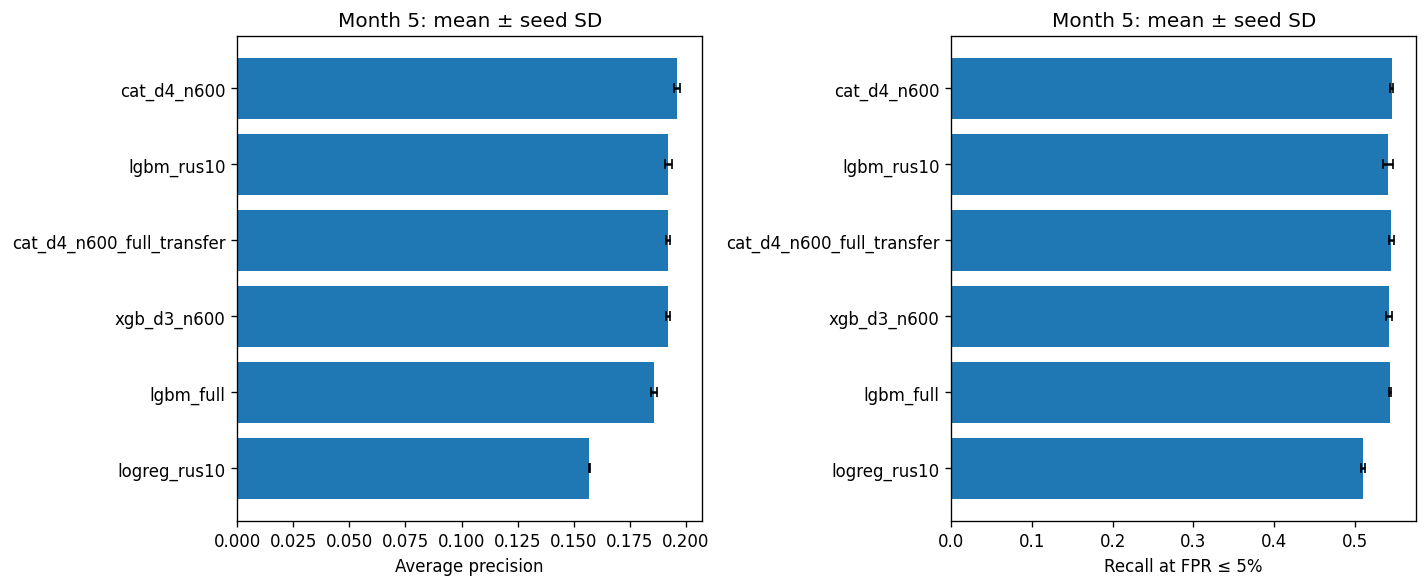

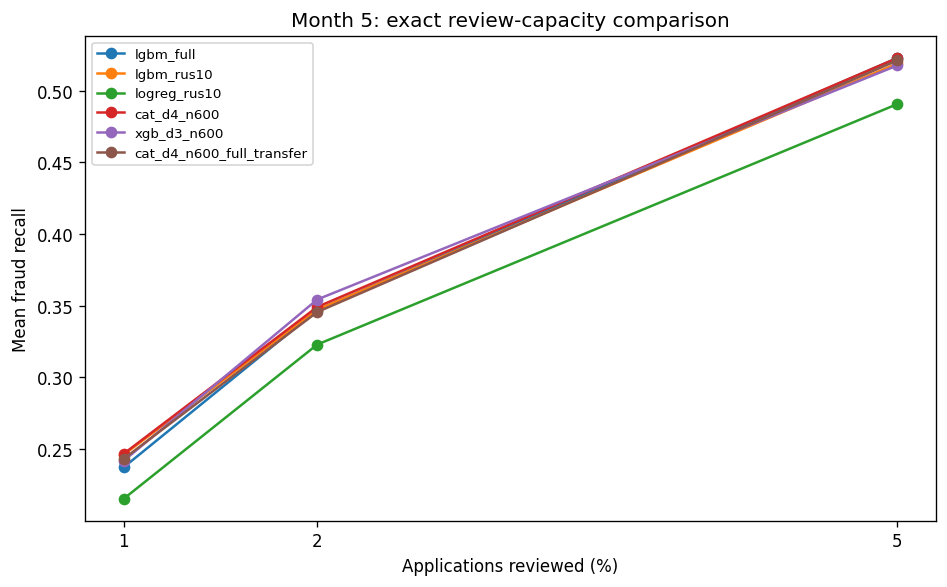

Completed fits: 24
Results: /content/drive/MyDrive/BT4012_grp_proj/results/model_comparison/model_comparison_20261115T184401Z_8e91a0
Models/predictions: /content/drive/MyDrive/BT4012_grp_proj/artifacts/model_comparison/model_comparison_20261115T184401Z_8e91a0


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
positions = np.arange(len(final_summary))
for ax, mean_col, sd_col, label in [
    (axes[0], 'ap_mean', 'ap_std', 'Average precision'),
    (axes[1], 'recall_at_fpr_mean', 'recall_at_fpr_std', 'Recall at FPR ≤ 5%'),
]:
    ax.barh(positions, final_summary[mean_col],
            xerr=final_summary[sd_col].fillna(0), capsize=3)
    ax.set_yticks(positions, final_summary['candidate'])
    ax.invert_yaxis()
    ax.set_xlabel(label)
    ax.set_title('Month 5: mean ± seed SD')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'model_comparison.png', bbox_inches='tight')
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5))
for candidate, frame in capacity_summary.groupby('candidate', sort=False):
    ax.plot(100 * frame['capacity'], frame['recall_mean'], marker='o', label=candidate)
ax.set(xlabel='Applications reviewed (%)', ylabel='Mean fraud recall',
       title='Month 5: exact review-capacity comparison')
ax.set_xticks([100 * v for v in REVIEW_CAPACITIES])
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'model_review_capacity.png', bbox_inches='tight')
plt.show()
plt.close(fig)

write_json('ensemble_input_manifest.json', {
    'run_name': RUN_NAME,
    'prepared_sha256': manifest['prepared_sha256'],
    'artifacts_directory_at_creation': str(ARTIFACTS_DIR),
    'validation_index_file': 'validation_index.parquet',
    'row_id_column': ROW_ID, 'target_column': TARGET,
    'prediction_score_column': 'score',
    'validation_months': VALIDATION_MONTHS, 'test_evaluated': False,
    'specifications': final_specs,
    'entries': final_metrics[[
        'candidate', 'family', 'treatment', 'seed', 'prediction_file', 'model_file',
        'validation_threshold', 'threshold_is_positive_infinity',
        'training_ids_sha256',
    ]].to_dict(orient='records'),
})
run_info['status'] = 'complete'
run_info['completed_fits'] = len(completed)
run_info['selected_specs'] = final_specs
run_info['transfer_challenger'] = challenger_id
run_info['highest_mean_ap_candidate'] = final_summary.iloc[0]['candidate']
write_json('run_info.json', run_info)
print('Completed fits:', len(completed))
print('Results:', RESULTS_DIR)
print('Models/predictions:', ARTIFACTS_DIR)


## 12. Findings and next step

Record which family has the highest mean AP, whether seed spread is large relative to differences, whether recall at 5% FPR agrees, and what happens at the 1/2/5% review budgets. Explain the treatment transfer result without claiming undersampling universally helps every model.

**Next: C2.** Inspect this comparison before choosing the previously bounded set of blends. An ensemble is optional and must beat a meaningful individual reference; adding models is not automatically an improvement. Keep the unweighted LightGBM reference even if another candidate leads on AP. Final months 6–7 remain reserved until configurations and decision rules are frozen.

**Reproducibility:** save/commit this executed notebook and small result CSV/JSON/figures. Add CatBoost and XGBoost to your repository requirements and record the versions in `run_info.json`. Keep data and large `artifacts/` files out of Git. The artifact directory contains candidate pipelines and native model files; `.joblib` pipelines include preprocessing. Reload them with `joblib.load(path)` and predict using a prepared dataframe ordered as `FEATURES`. Native classifier files alone require the matching saved preprocessing.

The screen, seed checks and transfer check all reuse month 5; these are selected development results, not unbiased future performance. Pipeline preprocessing differs intentionally by family. No causal conclusion about algorithms follows from a small unequal-compute search. Flagged fraud labels do not establish fraud prevented or monetary savings. Document AI assistance and ensure every team member can explain their contribution.
